# Mota Programming Assignment 3 — Data Mining
Association Analysis, CNN Image Classification, and BERT Multi-Label Text Classification.


## Setup and file paths
For local Jupyter, place this notebook, `Grocery_Items_0.csv`, the `Fashion-MINIST` folder, and your tweet files together. In Colab, mount Drive and set `BASE` to your assignment folder. `Path.cwd()` is the current working directory, not necessarily the notebook location.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf


BASE = Path("/Users/mozart/Desktop/Rowan Fall 2026/Data Mining/week 8")
GROCERY = BASE / 'RU_F22_DM1_Item_Datasets/Grocery_Items_0.csv'
FASHION = BASE / 'Fashion-MINIST'
TWEETS = BASE / 'student_6'  
print('Base:', BASE)
print('Grocery exists:', GROCERY.exists())


Base: /Users/mozart/Desktop/Rowan Fall 2026/Data Mining/week 8
Grocery exists: True


## 1. Association Rule Mining
### 1(a) Dataset exploration
Each row is one transaction; empty columns are ignored. Repeated products in the same transaction are counted once.

In [2]:
from collections import Counter
raw = pd.read_csv(GROCERY, dtype=str)
transactions = [sorted(set(str(v).strip() for v in row.dropna() if str(v).strip())) for _, row in raw.iterrows()]
counts = Counter(item for t in transactions for item in t)
print('Number of transactions:', len(transactions))
print('Number of unique items:', len(counts))
print('Top three items and transaction counts:', counts.most_common(3))

Number of transactions: 8000
Number of unique items: 165
Top three items and transaction counts: [('whole milk', 1227), ('other vegetables', 943), ('rolls/buns', 898)]


**Verified from the uploaded grocery CSV:** 8,000 transactions, 165 unique items. Three most frequent: whole milk (1,227), other vegetables (943), rolls/buns (898).

### 1(b) Apriori and association rules
Minimum support = 0.005; minimum confidence = 0.10. The top five are sorted by lift.

In [3]:
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules
te = TransactionEncoder()
encoded = pd.DataFrame(te.fit(transactions).transform(transactions), columns=te.columns_)
frequent = apriori(encoded, min_support=0.005, use_colnames=True)
rules = association_rules(frequent, metric='confidence', min_threshold=0.10)
print('Total rules:', len(rules))
top5 = rules.sort_values('lift', ascending=False).head(5).copy()
for col in ['antecedents','consequents']:
    top5[col] = top5[col].map(lambda s: ', '.join(sorted(s)))
display(top5[['antecedents','consequents','support','confidence','lift']])

Total rules: 22


,antecedents,consequents,support,confidence,lift
16,sausage,yogurt,0.00650,0.111588,1.328428
5,frankfurter,other vegetables,0.00500,0.135135,1.146427
17,shopping bags,soda,0.00525,0.109375,1.139323
10,pip fruit,rolls/buns,0.00550,0.113990,1.015498
12,pork,whole milk,0.00575,0.153846,1.003072


### 1(c) Parameter sensitivity

Number of association rules for each combination:


,0.002,0.005,0.010
0.05,236,58,10
0.10,64,22,4
0.15,8,1,0


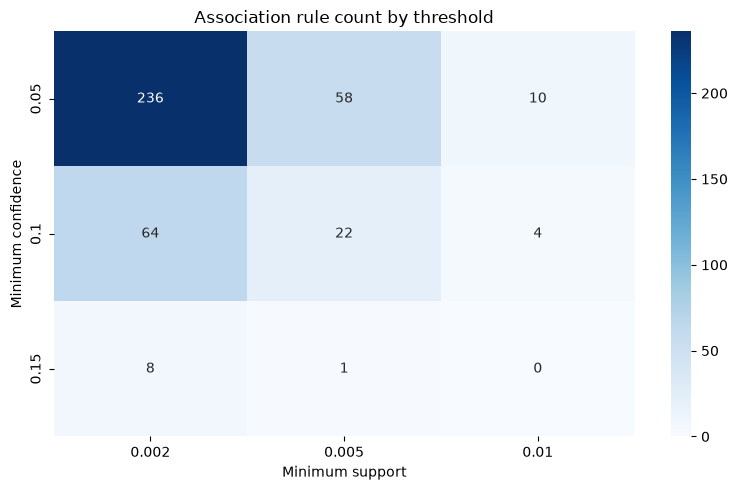

In [4]:
supports = [0.002, 0.005, 0.01]
confidences = [0.05, 0.10, 0.15]
heat = pd.DataFrame(index=confidences, columns=supports, dtype=int)
for support in supports:
    itemsets = apriori(encoded, min_support=support, use_colnames=True)
    for confidence in confidences:
        r = association_rules(itemsets, metric='confidence', min_threshold=confidence)
        heat.loc[confidence, support] = len(r)
print('Number of association rules for each combination:')
display(heat.astype(int))
plt.figure(figsize=(8, 5))
sns.heatmap(heat.astype(int), annot=True, fmt='d', cmap='Blues')
plt.xlabel('Minimum support')
plt.ylabel('Minimum confidence')
plt.title('Association rule count by threshold')
plt.tight_layout()
plt.show()

### 1(d) Interpretation
Increasing the minimum support and confidence decreases the number of association rules because fewer rules meet the requirements. For example, at a support of 0.002 and confidence of 0.05, there were 236 rules, while at a support of 0.010 and confidence of 0.15, there were 0 rules.

A rule can have high confidence but low lift when the item being predicted is already common in the dataset. This means high confidence does not always indicate a strong association. A lift close to 1 means there is little association between the items.

## 2. Image Classification Using CNN 
Using Fashion-MNIST classes **1 Trouser, 5 Sandal, 8 Bag, 9 Ankle Boot**, as selected in Assignment 1.

In [5]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split

SEED = 42
tf.keras.utils.set_random_seed(SEED)
CLASSES = [1, 5, 8, 9]
CLASS_NAMES = {1:'Trouser',5:'Sandal',8:'Bag',9:'Ankle Boot'}
train_file = FASHION / 'fashion-mnist_train.csv'
print('Fashion train file exists:', train_file.exists())
train_df = pd.read_csv(train_file)
selected = train_df[train_df['label'].isin(CLASSES)].copy()
X = selected.drop(columns=['label']).to_numpy(dtype='float32').reshape(-1,28,28,1) / 255.0
y_index = selected['label'].map({v:i for i,v in enumerate(CLASSES)}).to_numpy()
X_train, X_val, y_train_index, y_val_index = train_test_split(X, y_index, test_size=0.20, random_state=SEED, stratify=y_index)
y_train = keras.utils.to_categorical(y_train_index, 4)
y_val = keras.utils.to_categorical(y_val_index, 4)
print('Training:', X_train.shape, 'Validation:', X_val.shape)

Fashion train file exists: True
Training: (19200, 28, 28, 1) Validation: (4800, 28, 28, 1)


### 2(a) Baseline CNN
Two 3×3 convolution layers with 8 filters each, each followed by 2×2 max pooling; flatten, dense(16), dense(4, softmax). Adam optimizer, categorical cross-entropy, 20 epochs, and a fixed 20% validation split.

In [6]:
def make_cnn(second_kernel=3, second_filters=8, hidden_units=16):
    model = keras.Sequential([
        layers.Input(shape=(28,28,1)),
        layers.Conv2D(8, (3,3), activation='relu'),
        layers.MaxPooling2D((2,2)),
        layers.Conv2D(second_filters, (second_kernel,second_kernel), activation='relu'),
        layers.MaxPooling2D((2,2)),
        layers.Flatten(),
        layers.Dense(hidden_units, activation='relu'),
        layers.Dense(4, activation='softmax')
    ])
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return model

EPOCHS = 20  
BATCH_SIZE = 64

def fit_cnn(model):
    return model.fit(X_train, y_train, validation_data=(X_val,y_val), epochs=EPOCHS, batch_size=BATCH_SIZE, verbose=1)

baseline = make_cnn()
history_baseline = fit_cnn(baseline)
print('Final train accuracy:', history_baseline.history['accuracy'][-1])
print('Final validation accuracy:', history_baseline.history['val_accuracy'][-1])

Epoch 1/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9102 - loss: 0.2728 - val_accuracy: 0.9756 - val_loss: 0.0786
Epoch 2/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9792 - loss: 0.0655 - val_accuracy: 0.9808 - val_loss: 0.0609
Epoch 3/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9840 - loss: 0.0522 - val_accuracy: 0.9842 - val_loss: 0.0523
Epoch 4/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9859 - loss: 0.0450 - val_accuracy: 0.9858 - val_loss: 0.0456
Epoch 5/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9877 - loss: 0.0398 - val_accuracy: 0.9869 - val_loss: 0.0408
Epoch 6/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9884 - loss: 0.0366 - val_accuracy: 0.9875 - val_loss: 0.0375
Epoch 7/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9893 - loss: 0.0340 - val_accuracy: 0.9885 - val_loss: 0.0353
Epoch 8/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9896 - loss: 0.0317 - val_accuracy: 0.

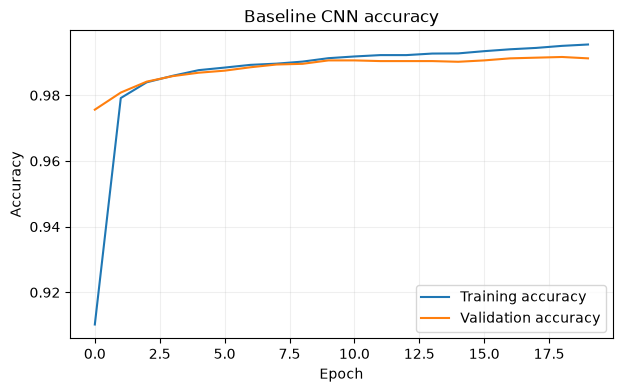

In [7]:
def plot_history(history, title):
    plt.figure(figsize=(7,4))
    plt.plot(history.history['accuracy'], label='Training accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.title(title)
    plt.legend()
    plt.grid(alpha=.2)
    plt.show()
plot_history(history_baseline, 'Baseline CNN accuracy')

### 2(b) CNN architecture experiment


In [8]:
BANNER_LAST_DIGIT = 1
assert isinstance(BANNER_LAST_DIGIT, int) and 0 <= BANNER_LAST_DIGIT <= 9, 'Enter your Banner ID last digit.'
if BANNER_LAST_DIGIT <= 3:
    variations = [('Second kernel 5x5', {'second_kernel':5}), ('Second kernel 7x7', {'second_kernel':7})]
elif BANNER_LAST_DIGIT <= 6:
    variations = [('Second filters 4', {'second_filters':4}), ('Second filters 16', {'second_filters':16})]
else:
    variations = [('Hidden neurons 8', {'hidden_units':8}), ('Hidden neurons 32', {'hidden_units':32})]
print('Banner ID last digit:', BANNER_LAST_DIGIT)
models = {'Baseline': baseline}
histories = {'Baseline': history_baseline}
for name, kwargs in variations:
    print('Training:', name)
    tf.keras.utils.set_random_seed(SEED)
    model = make_cnn(**kwargs)
    models[name] = model
    histories[name] = fit_cnn(model)

Banner ID last digit: 1
Training: Second kernel 5x5
Epoch 1/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9080 - loss: 0.2672 - val_accuracy: 0.9777 - val_loss: 0.0714
Epoch 2/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9800 - loss: 0.0649 - val_accuracy: 0.9827 - val_loss: 0.0527
Epoch 3/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9826 - loss: 0.0514 - val_accuracy: 0.9854 - val_loss: 0.0453
Epoch 4/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9851 - loss: 0.0438 - val_accuracy: 0.9856 - val_loss: 0.0416
Epoch 5/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9862 - loss: 0.0394 - val_accuracy: 0.9865 - val_loss: 0.0385
Epoch 6/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9876 - loss: 0.0357 - val_accuracy: 0.9877 - val_loss: 0.0338
Epoch 7/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9889 - loss: 0.0326 - val_accuracy: 0.9892 - val_loss: 0.0310
Epoch 8/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step 

### 2(c) Learning curves and comparison

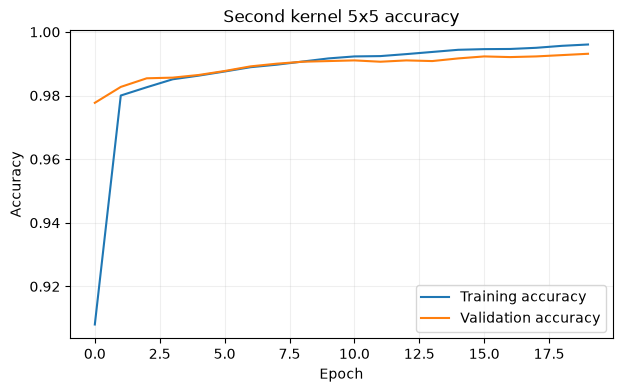

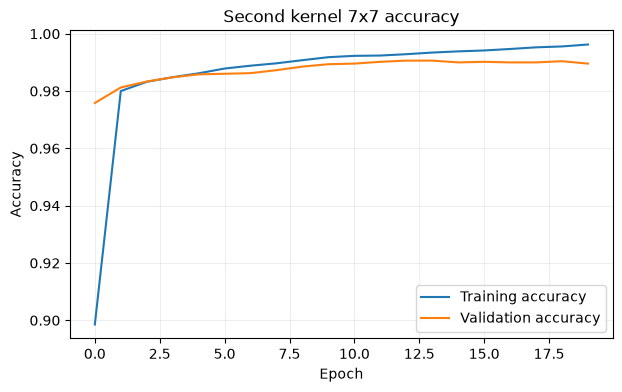

,Model,Trainable parameters,Final training accuracy,Final validation accuracy
0,Baseline,3948,0.995469,0.991250
1,Second kernel 5x5,3820,0.996042,0.993125
2,Second kernel 7x7,4460,0.996250,0.989583


Best validation accuracy: Second kernel 5x5


In [9]:
for name in [x[0] for x in variations]:
    plot_history(histories[name], name + ' accuracy')
comparison = pd.DataFrame([{
    'Model': name,
    'Trainable parameters': int(sum(np.prod(w.shape) for w in model.trainable_weights)),
    'Final training accuracy': histories[name].history['accuracy'][-1],
    'Final validation accuracy': histories[name].history['val_accuracy'][-1]
} for name, model in models.items()])
display(comparison)
print('Best validation accuracy:', comparison.loc[comparison['Final validation accuracy'].idxmax(), 'Model'])

### 2(d) Critical analysis — fill in after running
**Highest validation accuracy:** The second kernel 5×5 model had the highest validation accuracy of 99.31%, with 3,820 trainable parameters.

**Do more parameters always improve validation accuracy?** No, having more parameters does not always improve validation accuracy. The 7×7 model had the most parameters at 4,460, but its validation accuracy was the lowest at 98.96%. The 5×5 model had the fewest parameters and achieved the highest validation accuracy of 99.31%.

**Overfitting / underfitting:** All three models achieved high training and validation accuracy, which suggests that none of them were significantly underfitting. The 7×7 model had the largest difference between training and validation accuracy, which could indicate some overfitting. The 5×5 model had the smallest difference and performed better on the validation data.

## 3. Multi-Label Tweet Classification Using BERT 


In [10]:
import torch
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.metrics import f1_score

LABELS = ['anger','anticipation','disgust','fear','joy','love','optimism','pessimism','sadness','surprise','trust']
TRAIN_TWEETS = TWEETS / 'train.json'  # Update to your actual filenames
VAL_TWEETS = TWEETS / 'validation.json'
TEST_TWEETS = TWEETS / 'test.json'

print([(str(p), p.exists()) for p in (TRAIN_TWEETS,VAL_TWEETS,TEST_TWEETS)])

/opt/anaconda3/envs/datamining/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[('/Users/mozart/Desktop/Rowan Fall 2026/Data Mining/week 8/student_6/train.json', True), ('/Users/mozart/Desktop/Rowan Fall 2026/Data Mining/week 8/student_6/validation.json', True), ('/Users/mozart/Desktop/Rowan Fall 2026/Data Mining/week 8/student_6/test.json', True)]


In [11]:
import json

def load_tweets(path):
    with open(path, "r", encoding="utf-8") as f:
        data = [json.loads(line) for line in f if line.strip()]

    print("Number of records:", len(data))
    print("First record:", data[0])

    return data

sample = load_tweets(TRAIN_TWEETS)

Number of records: 3000
First record: {'ID': '2017-En-30430', 'Tweet': 'Watch this amazing live.ly broadcast by @broitzmax  #musically', 'anger': False, 'anticipation': True, 'disgust': False, 'fear': False, 'joy': True, 'love': False, 'optimism': True, 'pessimism': False, 'sadness': False, 'surprise': True, 'trust': True}


In [12]:
import numpy as np

LABELS = [
    'anger', 'anticipation', 'disgust', 'fear',
    'joy', 'love', 'optimism', 'pessimism',
    'sadness', 'surprise', 'trust'
]

def prepare_tweets(path):
    records = load_tweets(path)

    texts = [record['Tweet'] for record in records]

    labels = np.array([
        [float(record[label]) for label in LABELS]
        for record in records
    ], dtype=np.float32)

    return texts, labels

train_texts, train_y = prepare_tweets(TRAIN_TWEETS)
val_texts, val_y = prepare_tweets(VAL_TWEETS)
test_texts, test_y = prepare_tweets(TEST_TWEETS)

print("Training:", len(train_texts), train_y.shape)
print("Validation:", len(val_texts), val_y.shape)
print("Testing:", len(test_texts), test_y.shape)

Number of records: 3000
First record: {'ID': '2017-En-30430', 'Tweet': 'Watch this amazing live.ly broadcast by @broitzmax  #musically', 'anger': False, 'anticipation': True, 'disgust': False, 'fear': False, 'joy': True, 'love': False, 'optimism': True, 'pessimism': False, 'sadness': False, 'surprise': True, 'trust': True}
Number of records: 400
First record: {'ID': '2018-En-02394', 'Tweet': "@LeahRemini  A 'religion' that pushes people to suicide, and punishes you for doing the right thing?? #heartbreaking", 'anger': True, 'anticipation': False, 'disgust': True, 'fear': False, 'joy': False, 'love': False, 'optimism': False, 'pessimism': True, 'sadness': True, 'surprise': False, 'trust': False}
Number of records: 1500
First record: {'ID': '2018-En-02066', 'Tweet': 'After all of the Disney animated films are remade in live action, will they just reanimate them again?', 'anger': False, 'anticipation': True, 'disgust': False, 'fear': False, 'joy': False, 'love': False, 'optimism': True, '

### 3(a) Fine-tune BERT for five epochs

In [13]:
MODEL_NAME = 'google-bert/bert-base-uncased'
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
class TweetDataset(Dataset):
    def __init__(self, texts, labels):
        self.tokens = tokenizer(texts, padding='max_length', truncation=True, max_length=128)
        self.labels = torch.tensor(labels, dtype=torch.float32)
    def __len__(self): return len(self.labels)
    def __getitem__(self, i):
        return {**{k:torch.tensor(v[i],dtype=torch.long) for k,v in self.tokens.items()}, 'labels':self.labels[i]}

train_loader = DataLoader(TweetDataset(train_texts,train_y),batch_size=16,shuffle=True)
val_loader = DataLoader(TweetDataset(val_texts,val_y),batch_size=32)
test_loader = DataLoader(TweetDataset(test_texts,test_y),batch_size=32)
device = torch.device('cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu'))
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME,num_labels=11,problem_type='multi_label_classification').to(device)
optimizer = torch.optim.AdamW(model.parameters(),lr=2e-5)
print('Device:',device)

W1020 21:32:12.986000 77659 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 11024.96it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be igno

Device: mps


In [14]:
model = model.to(device)

print("Model device:", next(model.parameters()).device)
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

Model device: mps:0
Training batches: 188
Validation batches: 13
Testing batches: 47


Validation: 100%|██████████| 13/13 [00:04<00:00,  3.10it/s]


Epoch 1/5: train loss=0.1835, validation loss=0.3383


Validation: 100%|██████████| 13/13 [00:05<00:00,  2.44it/s]


Epoch 2/5: train loss=0.1568, validation loss=0.3491


Validation: 100%|██████████| 13/13 [00:05<00:00,  2.44it/s]


Epoch 3/5: train loss=0.1360, validation loss=0.3556


Validation: 100%|██████████| 13/13 [00:05<00:00,  2.33it/s]


Epoch 4/5: train loss=0.1174, validation loss=0.3752


Validation: 100%|██████████| 13/13 [00:05<00:00,  2.29it/s]

Epoch 5/5: train loss=0.1001, validation loss=0.3869


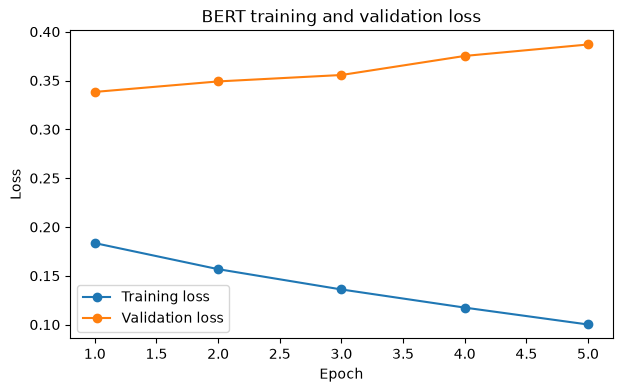

In [19]:

from tqdm.auto import tqdm

def run_epoch(loader, training=False):
    model.train(training)
    losses = []

    for batch in tqdm(loader, desc="Training" if training else "Validation"):
        batch = {key: value.to(device) for key, value in batch.items()}

        if training:
            optimizer.zero_grad()

        with torch.set_grad_enabled(training):
            outputs = model(**batch)
            loss = outputs.loss

            if training:
                loss.backward()
                optimizer.step()

        losses.append(loss.item())

    return float(np.mean(losses))


train_losses = []
val_losses = []

for epoch in range(1, 6):
    train_loss = run_epoch(train_loader, training=True)
    val_loss = run_epoch(val_loader, training=False)

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    print(f"Epoch {epoch}/5: train loss={train_loss:.4f}, validation loss={val_loss:.4f}")


plt.figure(figsize=(7, 4))
plt.plot(range(1, 6), train_losses, marker='o', label='Training loss')
plt.plot(range(1, 6), val_losses, marker='o', label='Validation loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('BERT training and validation loss')
plt.legend()
plt.show()


### 3(b)–(d) Test metrics

In [17]:
model.eval()
probs=[];truth=[]
with torch.no_grad():
    for batch in test_loader:
        labels=batch.pop('labels')
        outputs=model(**{k:v.to(device) for k,v in batch.items()})
        probs.append(torch.sigmoid(outputs.logits).cpu().numpy())
        truth.append(labels.numpy())
probs=np.concatenate(probs)
y_true=np.concatenate(truth).astype(int)
y_pred=(probs>=0.5).astype(int)
exact_match=np.mean(np.all(y_pred==y_true,axis=1))
at_least_one=np.mean(np.any((y_pred==1)&(y_true==1),axis=1))
micro_f1=f1_score(y_true,y_pred,average='micro',zero_division=0)
print(f'Exact-match accuracy: {exact_match:.4f}')
print(f'At-least-one-label accuracy: {at_least_one:.4f}')
print(f'Micro-F1: {micro_f1:.4f}')

Exact-match accuracy: 0.2673
At-least-one-label accuracy: 0.8500
Micro-F1: 0.6737


### 3(e) Comparison and interpretation
The BERT model achieved an exact-match accuracy of 26.73%, an at-least-one-label accuracy of 85.00%, and a micro-F1 score of 67.37%.

The exact-match accuracy was the lowest because the model must predict all 11 emotion labels correctly for each tweet. The at-least-one-label accuracy was much higher because the model only needs to predict one correct positive label. The micro-F1 score was 67.37%, which measures how well the model balances precision and recall across all the labels.

I observe that the model is better at identifying at least one correct emotion than predicting every emotion correctly. The micro-F1 score gives a better overall measurement because it considers both incorrect predictions and missed labels.